<a href="https://colab.research.google.com/github/lulluBackend/sistemas-inteligentes-colab/blob/main/fuel_consumption_exercise_solved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/xiptos/is_notes/blob/main/linear_regression_exercise_mpg.ipynb)

# Linear regression: predicting fuel consumption

In this exercise you will build a multiple linear regression model to predict a car's fuel efficiency, measured in **miles per gallon (mpg)**, using the [Auto MPG dataset](https://archive.ics.uci.edu/dataset/9/auto+mpg) from the UCI Machine Learning Repository.

Compared with the wine quality exercise, this dataset has a few real-world problems you have to deal with:

* **missing values**, encoded as `?` instead of an empty field;
* a **categorical** variable (`origin`) that is stored as a number;
* a text column that should not go into the model;
* relationships that are **not perfectly linear**.

### How this notebook works

* Cells with `...` or `# TODO` are for you to complete.
* Cells marked **Predict first** ask you to write what you *expect* **before** running the code. You should rely on your reasoning, not on whether the guess was right.
* Cells marked **Explain** must be answered in your own words and must refer to the **numbers you obtained**. Every student gets a slightly different subset of the data, so your numbers will be different from your colleagues'.
* `check(...)` cells test your work. If one fails, fix the cells above it before moving on.

## 0. Your student number

Write your student number below. It is used as the random seed, so it decides which cars end up in your dataset and in your test set. **Do not change it after you start.**

In [ ]:
STUDENT_ID = 12345  # your student number

assert isinstance(STUDENT_ID, int), "Set STUDENT_ID to your student number (an integer)."
SEED = STUDENT_ID % (2**32)

In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def check(condition, message):
    if not condition:
        raise AssertionError("❌ " + message)
    print("✅", message)

## 1. Dataset

### 1.1 Download

The data is a plain text file where the columns are separated by **whitespace** (not commas) and there is **no header line**. The column names come from the [dataset description](https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.names).

In [ ]:
import os
import urllib.request

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
FILE = "auto-mpg.data"
if not os.path.exists(FILE):
    urllib.request.urlretrieve(URL, FILE)

column_names = ["mpg", "cylinders", "displacement", "horsepower", "weight",
                "acceleration", "model_year", "origin", "car_name"]

### 1.2 Load

Open `auto-mpg.data` in a text editor (or run `!head auto-mpg.data`) and have a look at the raw file. Then complete the [`read_csv`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) call:

* the separator is one or more spaces (hint: the regular expression `r"\s+"`);
* the file has no header, so you have to pass the column names;
* missing values are written as `?`. Use the `na_values` parameter so pandas turns them into `NaN`.

In [ ]:
raw = pd.read_csv(FILE,
                  sep=r"\s+",
                  names=column_names,
                  na_values="?")

df = raw.sample(frac=0.9, random_state=SEED).reset_index(drop=True)
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,13.0,8,350.0,155.0,4502.0,13.5,72,1,buick lesabre custom
1,26.5,4,140.0,72.0,2565.0,13.6,76,1,ford pinto
2,15.0,8,350.0,145.0,4440.0,14.0,75,1,chevrolet bel air
3,17.0,6,163.0,125.0,3140.0,13.6,78,2,volvo 264gl
4,27.0,4,97.0,88.0,2100.0,16.5,72,3,toyota corolla 1600 (sw)


In [ ]:
check(raw.shape == (398, 9), "raw dataset has 398 rows and 9 columns")
check(raw["horsepower"].dtype == float, "horsepower was read as a number (the '?' became NaN)")

✅ raw dataset has 398 rows and 9 columns
✅ horsepower was read as a number (the '?' became NaN)


### 1.3 Understanding the dataset

Use `shape`, `info()` and `describe()` to explore the data.

In [ ]:
print(df.shape)
df.info()
df.describe()

(358, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 358 entries, 0 to 357
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           358 non-null    float64
 1   cylinders     358 non-null    int64  
 2   displacement  358 non-null    float64
 3   horsepower    353 non-null    float64
 4   weight        358 non-null    float64
 5   acceleration  358 non-null    float64
 6   model_year    358 non-null    int64  
 7   origin        358 non-null    int64  
 8   car_name      358 non-null    object 
dtypes: float64(5), int64(3), object(1)
memory usage: 25.3+ KB


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,358.000000,358.000000,358.000000,353.000000,358.000000,358.000000,358.000000,358.000000
mean,23.609777,5.438547,192.272346,104.002833,2957.343575,15.581285,75.983240,1.564246
std,7.785506,1.695395,104.000184,38.751869,844.354703,2.790081,3.686564,0.795686
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.525000,4.000000,100.250000,75.000000,2220.000000,14.000000,73.000000,1.000000
50%,23.000000,4.000000,145.500000,92.000000,2789.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,260.000000,125.000000,3568.250000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


**Explain:** What are the units of `weight` and `displacement`? What values does `origin` take, and what do you think they mean? Look at the [dataset description](https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.names) if you need to.

**Your answer:**



### 1.4 Missing values

Count the missing values in each column.

In [ ]:
df.isnull().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,5
weight,0
acceleration,0
model_year,0
origin,0
car_name,0


There are two common ways to deal with the missing values:

1. **drop** the rows that have them ([`dropna`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html));
2. **impute** them, for example with the median of the column ([`fillna`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html)).

Pick one, apply it, and justify your choice below.

In [ ]:
print("rows before:", len(df))
df = df.dropna().reset_index(drop=True)
print("rows after:", len(df))

rows before: 358
rows after: 353


In [ ]:
check(df.isnull().sum().sum() == 0, "no missing values left")

✅ no missing values left


**Explain:** Which strategy did you choose? How many rows did you have before and after? When would the other strategy be the better choice?

**Your answer:**



### 1.5 Preparing the columns

`car_name` is a text column that is (almost) unique for every car. Remove it from `df`.

In [ ]:
df = df.drop(columns="car_name")

`origin` is stored as 1, 2 and 3, but it is a **category**, not a quantity.

**Predict first:** If we left `origin` as the number 1, 2 or 3, what would the model be assuming about the difference between American (1), European (2) and Japanese (3) cars? Write your answer *before* doing the next step.

**Your answer:**



Replace the numbers with the region names (`1 → "usa"`, `2 → "europe"`, `3 → "japan"`) using [`map`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html), then turn the column into **one-hot** (dummy) variables with [`pd.get_dummies`](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html). Use `drop_first=True` and `dtype=float`.

In [ ]:
df["origin"] = df["origin"].map({1: "usa", 2: "europe", 3: "japan"})
df = pd.get_dummies(df, columns=["origin"], drop_first=True, dtype=float)
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_japan,origin_usa
0,13.0,8,350.0,155.0,4502.0,13.5,72,0.0,1.0
1,26.5,4,140.0,72.0,2565.0,13.6,76,0.0,1.0
2,15.0,8,350.0,145.0,4440.0,14.0,75,0.0,1.0
3,17.0,6,163.0,125.0,3140.0,13.6,78,0.0,0.0
4,27.0,4,97.0,88.0,2100.0,16.5,72,1.0,0.0


In [ ]:
check("origin" not in df.columns and "car_name" not in df.columns, "origin and car_name are no longer columns")
check(sum(c.startswith("origin_") for c in df.columns) == 2, "origin became 2 dummy columns")

✅ origin and car_name are no longer columns
✅ origin became 2 dummy columns


**Explain:** Why do we use `drop_first=True`? Which region was dropped, and what does that region become for the model?

**Your answer:**



### 1.6 Visual exploration

Draw a [`pairplot`](https://seaborn.pydata.org/generated/seaborn.pairplot.html) of `mpg`, `displacement`, `horsepower`, `weight` and `acceleration`, and a [`heatmap`](https://seaborn.pydata.org/generated/seaborn.heatmap.html) of the correlation matrix of all the columns (use `annot=True`).

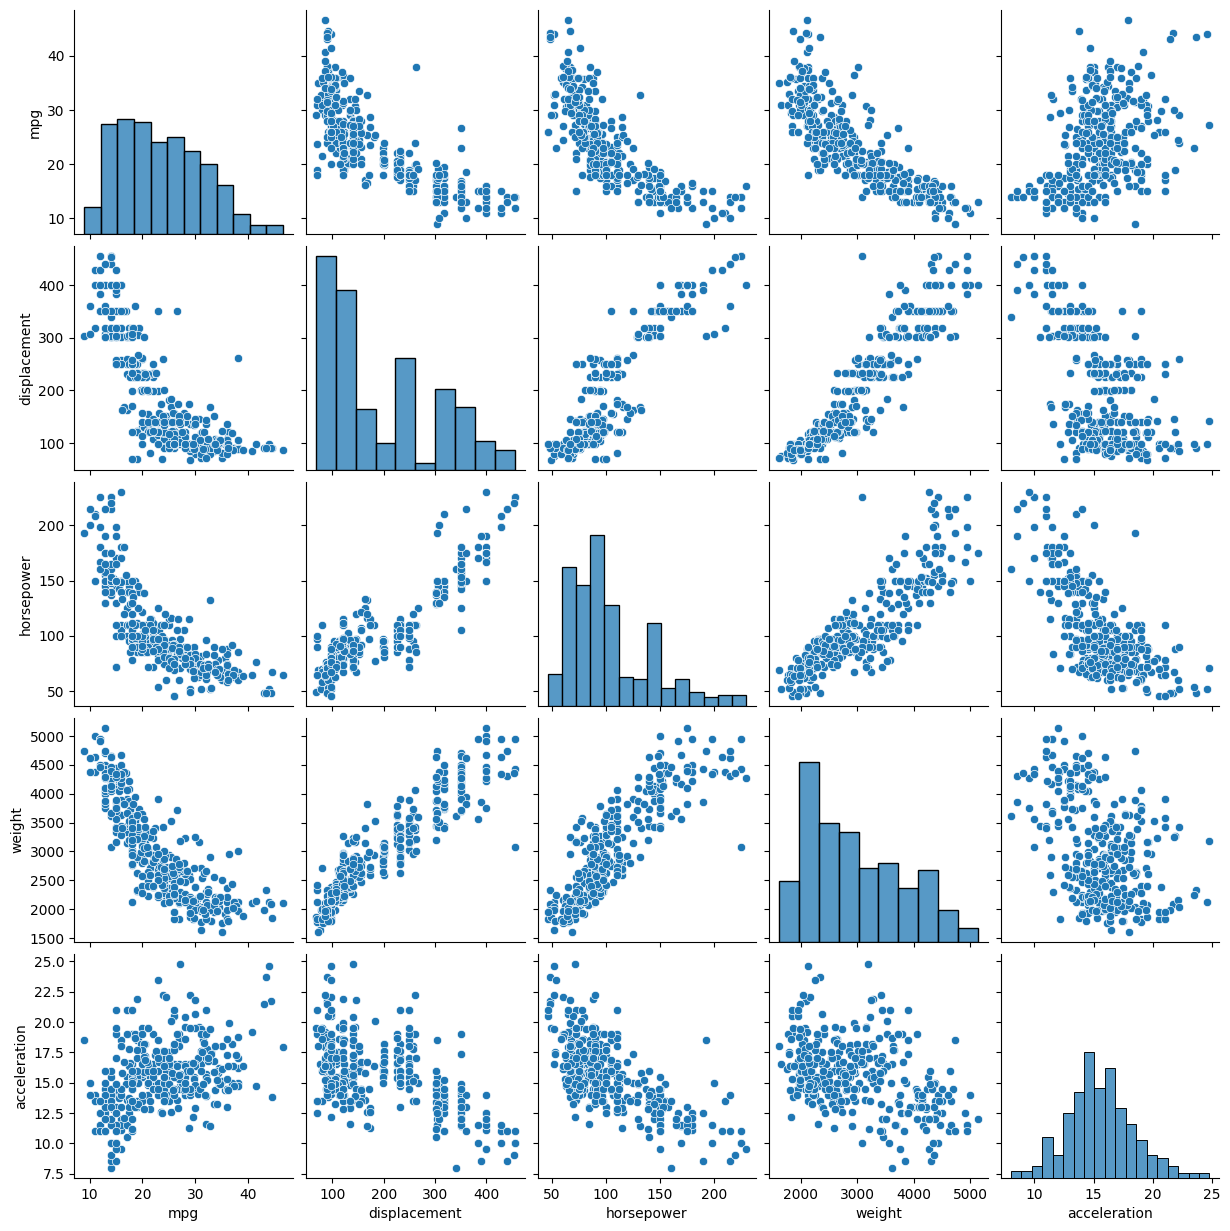

In [ ]:
sns.pairplot(df[["mpg", "displacement", "horsepower", "weight", "acceleration"]])
plt.show()

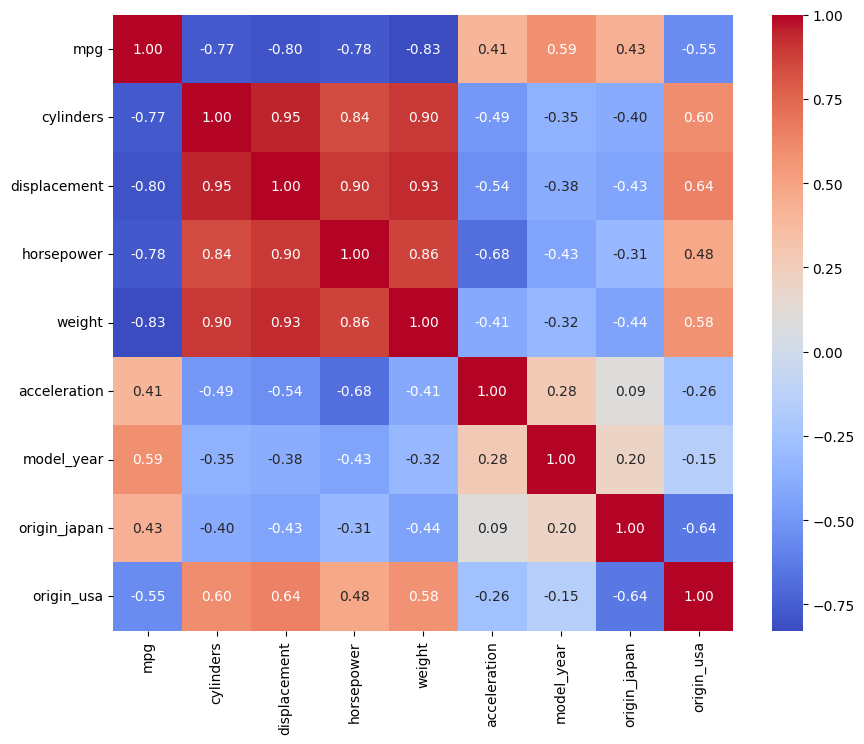

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

**Explain:**
1. Which variable has the strongest correlation with `mpg`? Is it positive or negative, and does that make physical sense?
2. Look at `mpg` vs `weight` and `mpg` vs `horsepower` in the pairplot. Is the relationship a straight line?
3. Find two input variables that are strongly correlated **with each other**. Why could that be a problem for interpreting the coefficients of a linear model?

**Your answer:**



## 2. Simple linear regression: mpg vs weight

Start with a single variable, as in `linear_regression.ipynb`. Use `weight` as $x$ and `mpg` as $y$.

**Predict first:** Look at the scatter plot. Roughly how many mpg do you expect a car to lose for every extra 1000 lbs? Write your guess, then fit the model.

**Your answer:**



In [ ]:
from sklearn.linear_model import LinearRegression

x_w = df[["weight"]]
y = df["mpg"]

simple = LinearRegression()
simple.fit(x_w, y)

print("slope:    ", simple.coef_[0])
print("intercept:", simple.intercept_)
print("mpg lost per 1000 lbs:", -simple.coef_[0] * 1000)

slope:     -0.007593557725134294
intercept: 46.05054210104496
mpg lost per 1000 lbs: 7.593557725134294


Draw the data together with the fitted line.

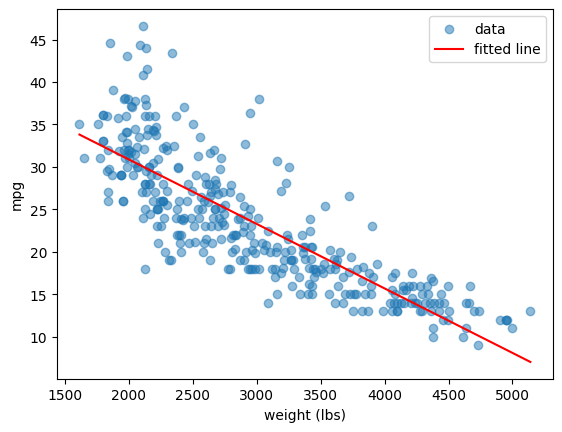

In [ ]:
wfit = np.linspace(df["weight"].min(), df["weight"].max(), 100)
mpg_fit = simple.predict(pd.DataFrame({"weight": wfit}))

plt.scatter(df["weight"], df["mpg"], alpha=0.5, label="data")
plt.plot(wfit, mpg_fit, color="red", label="fitted line")
plt.xlabel("weight (lbs)")
plt.ylabel("mpg")
plt.legend()
plt.show()

**Explain:** Write the slope as "a car that is 1000 lbs heavier gets ___ mpg less". Was your guess close? Does the line fit well for the lightest and the heaviest cars?

**Your answer:**



## 3. Multiple linear regression

### 3.1 Train/test split

Separate the target (`mpg`) from the input variables and split the data into 70% training and 30% test. Use `random_state=SEED`.

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="mpg")
y = df["mpg"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED)

In [ ]:
check("mpg" not in X.columns, "the target is not among the inputs")
check(abs(len(X_test) / len(X) - 0.3) < 0.01, "test set is 30% of the data")

✅ the target is not among the inputs
✅ test set is 30% of the data


### 3.2 Training

Train a `LinearRegression` model on the training set and show its coefficients in a table (a `pd.Series` indexed by the column names works well), sorted by value.

In [ ]:
lm = LinearRegression()
lm.fit(X_train, y_train)

coefs = pd.Series(lm.coef_, index=X.columns).sort_values()
coefs

,0
origin_usa,-3.154098
cylinders,-0.653432
origin_japan,-0.331600
acceleration,-0.026825
horsepower,-0.015324
weight,-0.007225
displacement,0.030037
model_year,0.801599


**Explain:**
1. What is the coefficient of `model_year` and what does it mean in plain words?
2. Compare the coefficient of `weight` here with the slope of the simple model in Section 2. Why are they different?
3. Can you say that the variable with the largest coefficient is the most important one? (Hint: look at the units of each variable.)

**Your answer:**



### 3.3 Evaluation

Before looking at the model's error we need something to compare it with. A **baseline** model always predicts the *mean mpg of the training set*, whatever the car.

**Predict first:** What $R^2$ do you expect the baseline to get? What $R^2$ do you expect the linear model to get?

**Your answer:**



Complete the function so that it returns the MAE, RMSE and $R^2$ of a set of predictions (use [`sklearn.metrics`](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)). Then evaluate the baseline and the linear model on the **test** set.

In [ ]:
from sklearn import metrics

def evaluate(y_true, y_pred):
    mae = metrics.mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(metrics.mean_squared_error(y_true, y_pred))
    r2 = metrics.r2_score(y_true, y_pred)
    return {"MAE": mae, "RMSE": rmse, "R2": r2}

baseline_pred = np.full(len(y_test), y_train.mean())
lm_pred = lm.predict(X_test)

results = pd.DataFrame({
    "baseline": evaluate(y_test, baseline_pred),
    "linear": evaluate(y_test, lm_pred),
}).T
results

,MAE,RMSE,R2
baseline,5.759434,7.331823,-0.013673
linear,2.690399,3.539466,0.763762


In [ ]:
check(abs(results.loc["baseline", "R2"]) < 0.1, "baseline R2 is close to 0")
check(results.loc["linear", "RMSE"] < results.loc["baseline", "RMSE"], "linear model beats the baseline")

✅ baseline R2 is close to 0
✅ linear model beats the baseline


**Explain:** Why is the baseline $R^2$ close to zero (and possibly a little negative)? Using your RMSE, how far off (in mpg) is a typical prediction of the linear model?

**Your answer:**



### 3.4 Residuals

A residual is $y - \hat{y}$. Plot the residuals of the test set against the predicted values, with a horizontal line at 0.

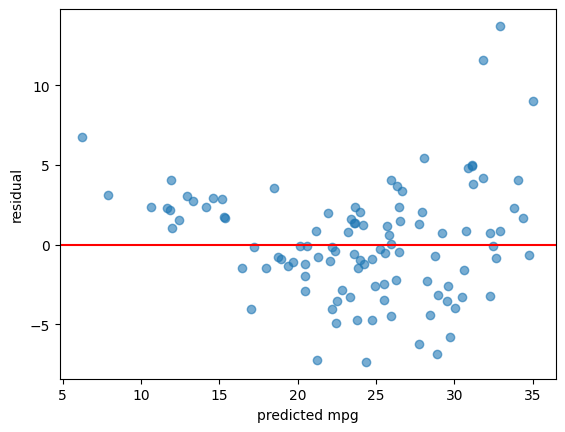

In [ ]:
residuals = y_test - lm_pred

plt.scatter(lm_pred, residuals, alpha=0.6)
plt.axhline(0, color="red")
plt.xlabel("predicted mpg")
plt.ylabel("residual")
plt.show()

**Explain:** If the model were a good description of the data, the residuals would look like random noise around 0. Do you see a pattern (for example a "U" shape, or a spread that grows)? What does it tell you about the model?

**Your answer:**



## 4. Improve the model

The plots in Sections 1.6 and 3.4 suggest that the relationship is not linear. Try **at least two** ideas to lower the test RMSE and record each result in the `experiments` table. Some ideas:

* add squared terms, e.g. `weight**2` or `horsepower**2`;
* predict `np.log(mpg)` instead of `mpg` (remember to convert the predictions back with `np.exp` before computing the metrics!);
* predict fuel consumption `1 / mpg` instead of `mpg` (again, convert back);
* remove variables that are redundant.

Always fit on the training set and evaluate on the test set, using the same split as before.

In [ ]:
experiments = {"linear (all features)": evaluate(y_test, lm_pred)}

# Idea 1: squared terms
def add_squares(X):
    X = X.copy()
    X["weight2"] = X["weight"] ** 2
    X["horsepower2"] = X["horsepower"] ** 2
    return X

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lm_sq = make_pipeline(StandardScaler(), LinearRegression()).fit(add_squares(X_train), y_train)
experiments["squared weight & horsepower"] = evaluate(y_test, lm_sq.predict(add_squares(X_test)))

# Idea 2: log(mpg) target
lm_log = LinearRegression().fit(X_train, np.log(y_train))
experiments["log(mpg) target"] = evaluate(y_test, np.exp(lm_log.predict(X_test)))

# Idea 3: 1/mpg target
lm_inv = LinearRegression().fit(X_train, 1 / y_train)
experiments["1/mpg target"] = evaluate(y_test, 1 / lm_inv.predict(X_test))

# Idea 4: squared terms + log(mpg)
lm_sq_log = make_pipeline(StandardScaler(), LinearRegression()).fit(add_squares(X_train), np.log(y_train))
experiments["squared + log(mpg)"] = evaluate(y_test, np.exp(lm_sq_log.predict(add_squares(X_test))))

pd.DataFrame(experiments).T.sort_values("RMSE")

,MAE,RMSE,R2
squared + log(mpg),2.112809,2.917088,0.839538
squared weight & horsepower,2.128870,2.947264,0.836201
1/mpg target,2.249450,3.005847,0.829624
log(mpg) target,2.276343,3.122298,0.816167
linear (all features),2.690399,3.539466,0.763762


**Explain:** Which idea worked best on *your* test set? Why do you think it helped? Is the model with squared terms still a "linear" regression?

**Your answer:**



## 5. Summary

Run the cell below and do not edit it. Your teacher can reproduce these numbers from your student number.

In [ ]:
print("Student:", STUDENT_ID)
print("Rows after cleaning:", len(df))
print(pd.DataFrame(experiments).T.round(3).to_string())

Student: 12345
Rows after cleaning: 353
                               MAE   RMSE     R2
linear (all features)        2.690  3.539  0.764
squared weight & horsepower  2.129  2.947  0.836
log(mpg) target              2.276  3.122  0.816
1/mpg target                 2.249  3.006  0.830
squared + log(mpg)           2.113  2.917  0.840


### AI usage declaration

If you used an AI tool (ChatGPT, Copilot, Gemini, Claude, ...) in this exercise, say **which one**, **for which sections**, and **what you asked it**. You may be asked to explain or change any cell of this notebook in class.

**Your answer:**

